In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import RocCurveDisplay
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [3]:
df = pd.read_csv(
    "rainfall_raw_50k.csv",
    dtype=str,
    keep_default_na=False
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,day,pressure,maxtemp,temperature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,16,1002.0,25.3,24.0,22.5,17.6,65.0,46.0,no,5.6,SW,8.8
1,104,1005.0,34.9,28.7,25.9,20.0,50.0,63.0,no,N/A,SE,8.2
2,195,1010.8,34.0,32.0,30.0,28.5,70.0,81.0,no,3.3,NE,2.8
3,81,1022.2,35.6,33.3,31.7,28.8,86.0,24.0,no,9.1,SW,19.4
4,274,1003.6,31.9,27.3,21.2,24.5,75.0,80.0,yes,1.7,N,36.5


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 50000
Number of columns: 12


In [6]:
print(df.columns.tolist())

['day', 'pressure', 'maxtemp', 'temperature', 'mintemp', 'dewpoint', 'humidity', 'cloud', 'rainfall', 'sunshine', 'winddirection', 'windspeed']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   day            50000 non-null  object
 1   pressure       50000 non-null  object
 2   maxtemp        50000 non-null  object
 3   temperature    50000 non-null  object
 4   mintemp        50000 non-null  object
 5   dewpoint       50000 non-null  object
 6   humidity       50000 non-null  object
 7   cloud          50000 non-null  object
 8   rainfall       50000 non-null  object
 9   sunshine       50000 non-null  object
 10  winddirection  50000 non-null  object
 11  windspeed      50000 non-null  object
dtypes: object(12)
memory usage: 4.6+ MB


In [8]:
missing_tokens = ["", "NA", "N/A", "null", "None", "?"]

missing_report = df.isin(missing_tokens).sum()

print("Missing values / tokens in each column:")
print(missing_report)

Missing values / tokens in each column:
day               575
pressure         1781
maxtemp          1203
temperature      1354
mintemp          1191
dewpoint         1905
humidity         2229
cloud            2366
rainfall          296
sunshine         2840
winddirection    1741
windspeed        1644
dtype: int64


In [9]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 120


In [12]:
for column in df.columns:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts().head(10))


Column: day
Unique values: 373
day
       275
347    181
172    167
299    165
134    164
277    164
280    163
192    163
271    163
311    162
Name: count, dtype: int64

Column: pressure
Unique values: 562
pressure
           940
unknown    472
NA         422
N/A        419
1012.7     272
1012.3     262
1013.7     258
1014.7     257
1012.4     254
1011.5     252
Name: count, dtype: int64

Column: maxtemp
Unique values: 409
maxtemp
           625
unknown    327
NA         290
N/A        288
28.6       283
28.8       276
32.2       273
28.0       273
32.1       273
28.1       272
Name: count, dtype: int64

Column: temperature
Unique values: 397
temperature
           693
unknown    332
N/A        332
NA         329
25.9       292
24.9       289
23.8       287
28.6       284
20.6       284
22.2       281
Name: count, dtype: int64

Column: mintemp
Unique values: 417
mintemp
           589
N/A        309
NA         293
22.0       280
18.5       279
23.5       278
22.7       278
23.4     

In [13]:
print(df["rainfall"].value_counts(dropna=False))

print("\nPercentage distribution:")
print(
    df["rainfall"].value_counts(normalize=True, dropna=False).mul(100).round(2)
)

rainfall
no         33396
yes        15025
YES          151
maybe        145
dry          140
0            140
             139
Yes          139
 Rain        133
No           128
1            122
NO           115
NA            81
N/A           76
unknown       70
Name: count, dtype: int64

Percentage distribution:
rainfall
no         66.79
yes        30.05
YES         0.30
maybe       0.29
dry         0.28
0           0.28
            0.28
Yes         0.28
 Rain       0.27
No          0.26
1           0.24
NO          0.23
NA          0.16
N/A         0.15
unknown     0.14
Name: proportion, dtype: float64


In [14]:
numeric_columns = [
    "pressure",
    "maxtemp",
    "temperature",
    "mintemp",
    "dewpoint",
    "humidity",
    "cloud",
    "sunshine",
    "windspeed"
]

for column in numeric_columns:
    converted = pd.to_numeric(df[column], errors="coerce")
    invalid = converted.isna() & ~df[column].isin(missing_tokens)

    print(f"{column}: {invalid.sum()} invalid numeric values")


pressure: 620 invalid numeric values
maxtemp: 327 invalid numeric values
temperature: 441 invalid numeric values
mintemp: 273 invalid numeric values
dewpoint: 490 invalid numeric values
humidity: 685 invalid numeric values
cloud: 747 invalid numeric values
sunshine: 724 invalid numeric values
windspeed: 545 invalid numeric values


In [15]:
numeric_summary = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
).describe().T

print(numeric_summary)

               count         mean        std    min     25%     50%     75%  \
pressure     47599.0  1010.468751  76.804555 -999.0  1007.6  1013.1  1018.4   
maxtemp      48470.0    29.019402   6.597375    4.0    24.2    29.0    33.9   
temperature  48205.0    23.623900  39.282369 -999.0    20.2    25.0    29.8   
mintemp      48536.0    21.008563   6.611080   -3.5    16.1    21.0    25.9   
dewpoint     47605.0    19.313360   7.295204   -5.5    14.2    19.3    24.5   
humidity     47086.0    68.628000  18.712573   -5.0    56.0    69.0    82.0   
cloud        46887.0    64.014823  22.316404  -10.0    49.0    65.0    80.0   
sunshine     46436.0     4.449309   2.668166    0.0     2.4     4.3     6.3   
windspeed    47811.0    12.475566  38.238428   -3.0     5.6     9.4    14.8   

                max  
pressure     1200.0  
maxtemp        50.0  
temperature    75.0  
mintemp        43.5  
dewpoint       38.0  
humidity      145.0  
cloud         150.0  
sunshine       14.0  
windspeed  

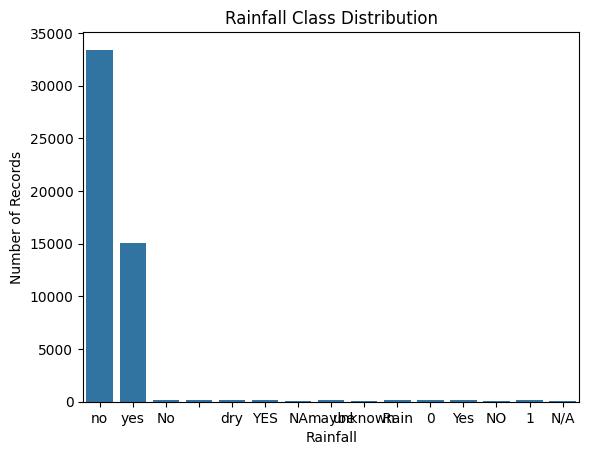

In [16]:
sns.countplot(data=df, x="rainfall")

plt.title("Rainfall Class Distribution")
plt.xlabel("Rainfall")
plt.ylabel("Number of Records")
plt.show()

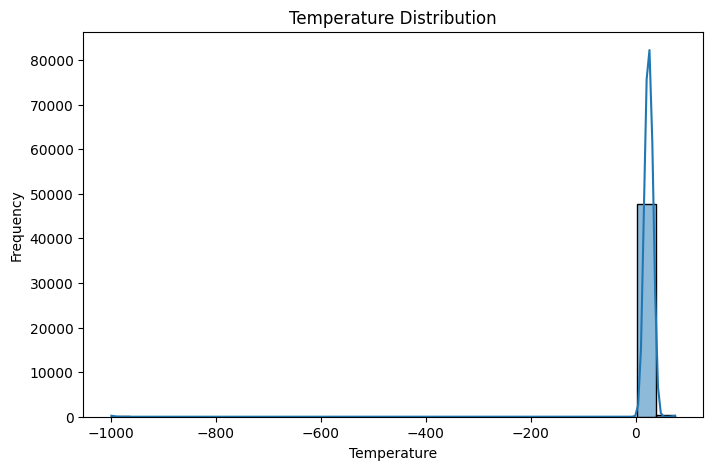

In [17]:
temperature = pd.to_numeric(
    df["temperature"],
    errors="coerce"
).dropna()

plt.figure(figsize=(8, 5))
sns.histplot(temperature, bins=30, kde=True)

plt.title("Temperature Distribution")
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.show()

In [22]:
df_clean = df.copy()

In [19]:
df_clean = df_clean.replace(
    r"^\s*(?:NA|N/A|null|None|\?)\s*$",
    np.nan,
    regex=True
)

df_clean = df_clean.replace(r"^\s*$", np.nan, regex=True)

print("Missing values after standardization:")
print(df_clean.isna().sum())

Missing values after standardization:
day               575
pressure         1781
maxtemp          1203
temperature      1354
mintemp          1191
dewpoint         1905
humidity         2229
cloud            2366
rainfall          296
sunshine         2840
winddirection    1741
windspeed        1644
dtype: int64


In [23]:
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

print(df_clean[numeric_columns].dtypes)

pressure       float64
maxtemp        float64
temperature    float64
mintemp        float64
dewpoint       float64
humidity       float64
cloud          float64
sunshine       float64
windspeed      float64
dtype: object


In [24]:
valid_ranges = {
    "pressure": (850, 1100),
    "maxtemp": (-30, 60),
    "temperature": (-30, 60),
    "mintemp": (-40, 50),
    "dewpoint": (-50, 40),
    "humidity": (0, 100),
    "cloud": (0, 100),
    "sunshine": (0, 24),
    "windspeed": (0, 200)
}

for column, (lower, upper) in valid_ranges.items():
    invalid_mask = (
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    )

    print(f"{column}: {invalid_mask.sum()} out-of-range values")
    df_clean.loc[invalid_mask, column] = np.nan


pressure: 147 out-of-range values
maxtemp: 0 out-of-range values
temperature: 138 out-of-range values
mintemp: 0 out-of-range values
dewpoint: 0 out-of-range values
humidity: 198 out-of-range values
cloud: 186 out-of-range values
sunshine: 0 out-of-range values
windspeed: 134 out-of-range values


In [25]:
categorical_columns = ["day", "winddirection"]

for column in categorical_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
        .str.upper()
    )

print(df_clean[categorical_columns].head())


   day winddirection
0   16            SW
1  104            SE
2  195            NE
3   81            SW
4  274             N


In [26]:
valid_directions = [
    "N", "NE", "E", "SE",
    "S", "SW", "W", "NW"
]

invalid_direction = ~df_clean["winddirection"].isin(
    valid_directions
)

print("Invalid wind directions:", invalid_direction.sum())

df_clean.loc[invalid_direction, "winddirection"] = np.nan

Invalid wind directions: 5198


In [29]:
df_clean["rainfall"] = (
    df_clean["rainfall"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print(df_clean["rainfall"].value_counts(dropna=False))

rainfall
no     33639
yes    15315
Name: count, dtype: Int64


In [28]:
valid_target = df_clean["rainfall"].isin(["yes", "no"])

print("Rows with invalid target:", (~valid_target).sum())

df_clean = df_clean.loc[valid_target].copy()

print("Shape after target cleaning:", df_clean.shape)

Rows with invalid target: 1046
Shape after target cleaning: (48954, 12)


In [30]:
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate rows found:", duplicates_before)
print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows found: 118
Shape after removing duplicates: (48836, 12)


In [31]:
print("Raw dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isna().sum())

print("\nTarget distribution:")
print(df_clean["rainfall"].value_counts())

Raw dataset shape: (50000, 12)
Cleaned dataset shape: (48836, 12)

Missing values after cleaning:
day                 0
pressure         2499
maxtemp          1503
temperature      1891
mintemp          1434
dewpoint         2349
humidity         3032
cloud            3221
rainfall            0
sunshine         3475
winddirection    5076
windspeed        2252
dtype: int64

Target distribution:
rainfall
no     33560
yes    15276
Name: count, dtype: Int64


In [33]:
processed_folder = Path("data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

processed_file = processed_folder / "rainfall_cleaned.csv"

df_clean.to_csv(processed_file, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", processed_file.resolve())
print("Final dataset shape:", df_clean.shape)


Cleaned dataset saved successfully!
File location: C:\Users\anami\Rainfall Prediction\data\processed\rainfall_cleaned.csv
Final dataset shape: (48836, 12)


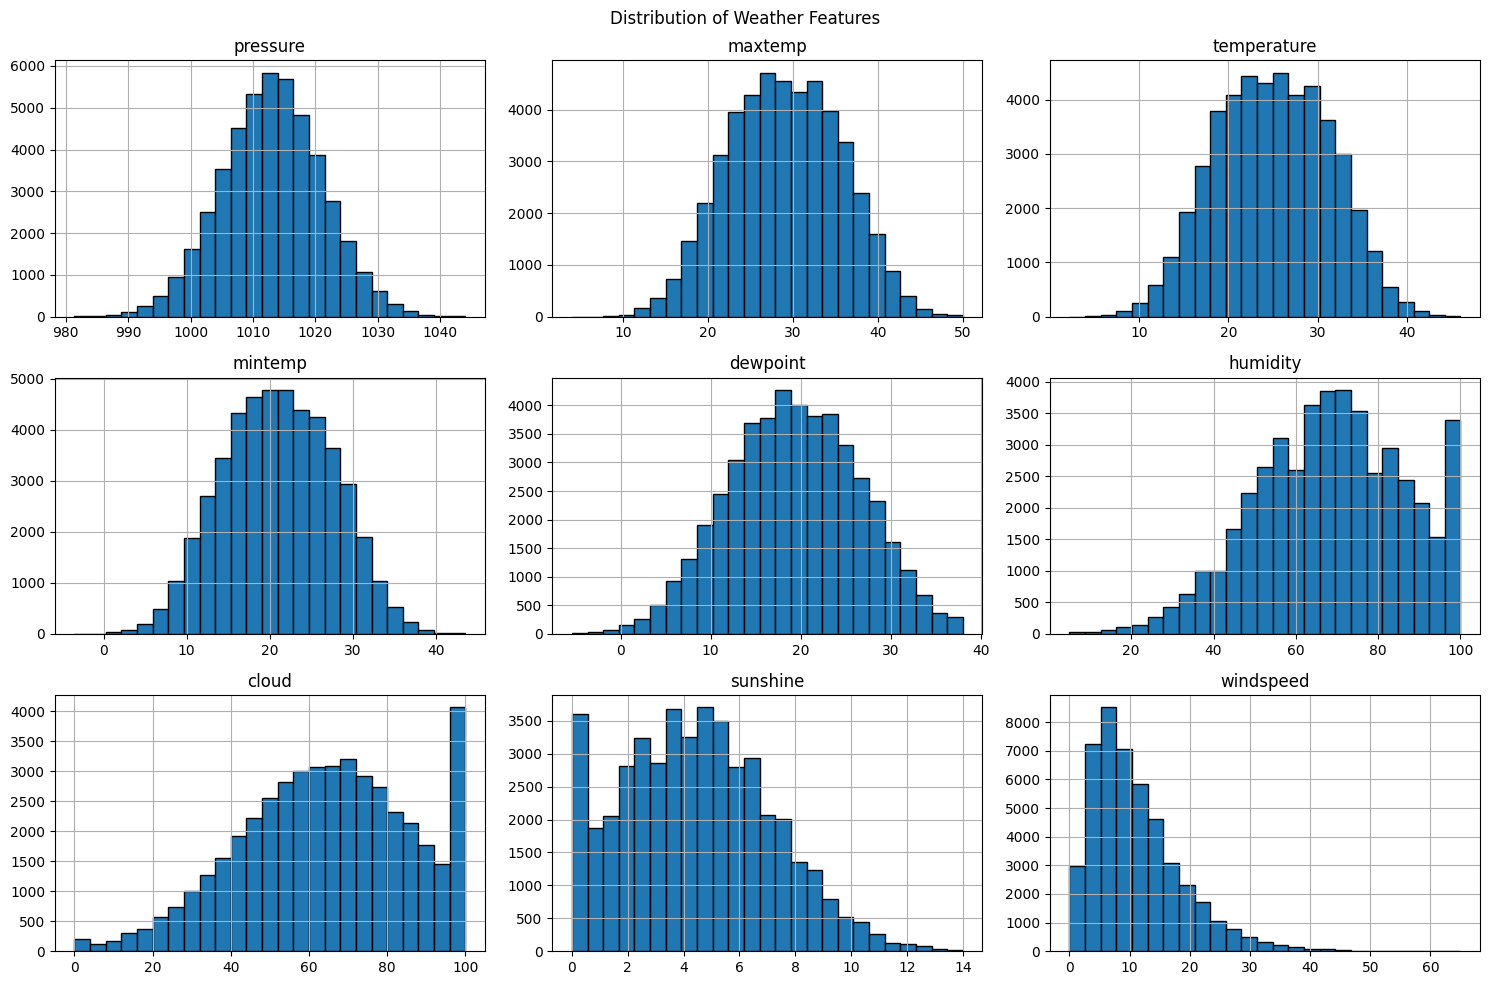

In [34]:
numeric_features = [
    "pressure", "maxtemp", "temperature", "mintemp",
    "dewpoint", "humidity", "cloud", "sunshine", "windspeed"
]

df_clean[numeric_features].hist(
    figsize=(15, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Weather Features")
plt.tight_layout()
plt.show()


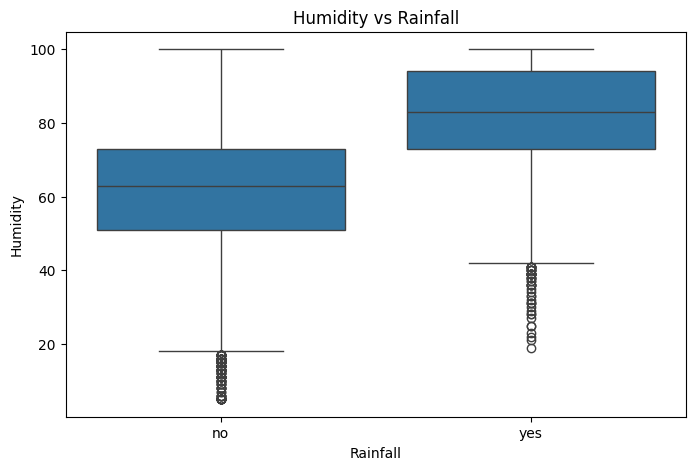

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="rainfall",
    y="humidity"
)

plt.title("Humidity vs Rainfall")
plt.xlabel("Rainfall")
plt.ylabel("Humidity")
plt.show()


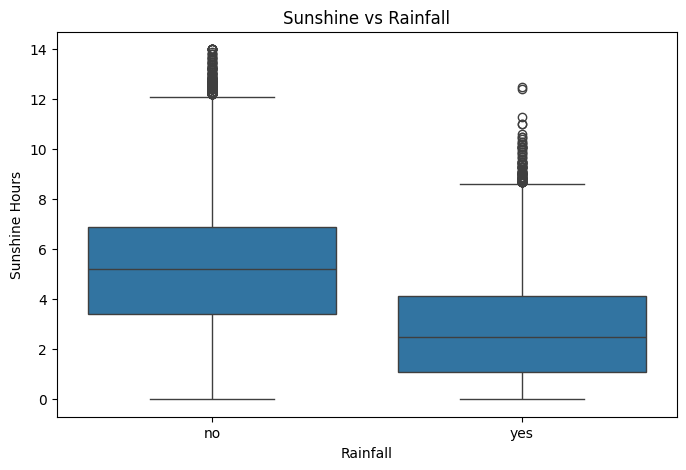

In [36]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="rainfall",
    y="sunshine"
)

plt.title("Sunshine vs Rainfall")
plt.xlabel("Rainfall")
plt.ylabel("Sunshine Hours")
plt.show()


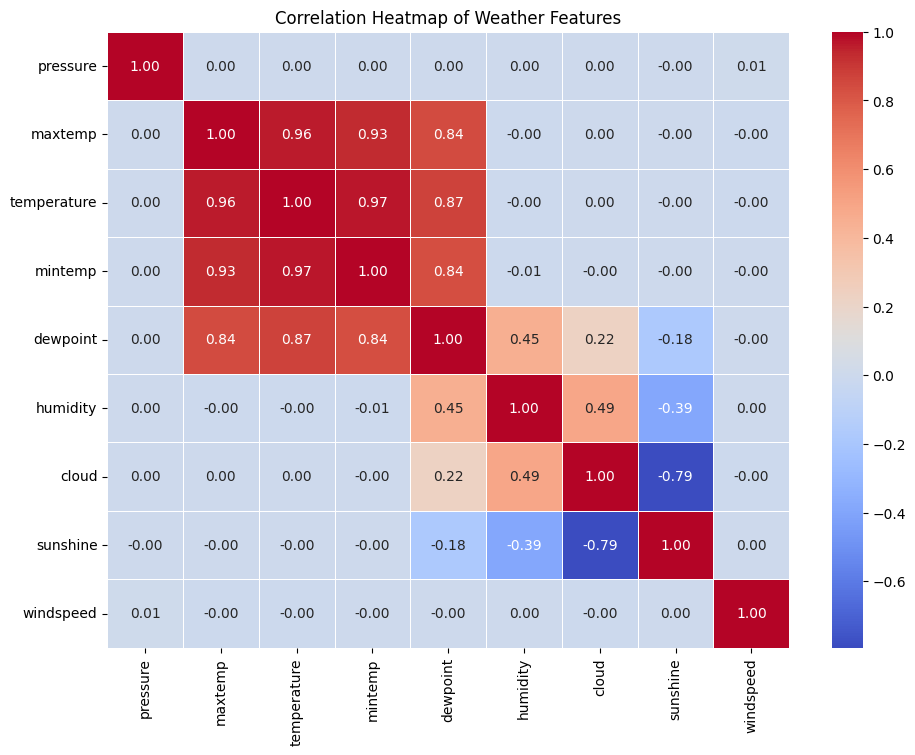

In [37]:
correlation_matrix = df_clean[numeric_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Weather Features")
plt.show()


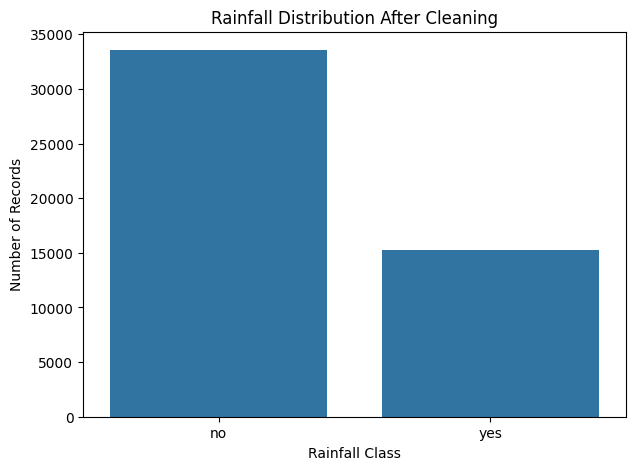

In [38]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="rainfall"
)

plt.title("Rainfall Distribution After Cleaning")
plt.xlabel("Rainfall Class")
plt.ylabel("Number of Records")
plt.show()


In [39]:
rainfall_rate = (
    df_clean.groupby("rainfall")[numeric_features]
    .mean()
    .T
)

print(rainfall_rate.round(2))


rainfall          no      yes
pressure     1013.59  1011.83
maxtemp        29.04    28.99
temperature    25.03    24.99
mintemp        21.03    20.97
dewpoint       18.14    21.89
humidity       62.33    82.38
cloud          56.92    79.55
sunshine        5.22     2.75
windspeed      10.98    11.29


In [40]:
eda_observations = [
    "Observation 1: __________________________",
    "Observation 2: __________________________",
    "Observation 3: __________________________"
]

for observation in eda_observations:
    print(observation)

Observation 1: __________________________
Observation 2: __________________________
Observation 3: __________________________


In [41]:
target_column = "rainfall"

feature_columns = [
    column for column in df_clean.columns
    if column != target_column
]

X = df_clean[feature_columns].copy()
y = df_clean[target_column].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())


Input features shape: (48836, 11)
Target shape: (48836,)

Input columns:
['day', 'pressure', 'maxtemp', 'temperature', 'mintemp', 'dewpoint', 'humidity', 'cloud', 'sunshine', 'winddirection', 'windspeed']

Target classes:
rainfall
no     33560
yes    15276
Name: count, dtype: Int64


In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training rows: 39068
Testing rows: 9768

Training target distribution:
rainfall
no     0.687
yes    0.313
Name: proportion, dtype: Float64

Testing target distribution:
rainfall
no     0.687
yes    0.313
Name: proportion, dtype: Float64


In [44]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['pressure', 'maxtemp', 'temperature', 'mintemp', 'dewpoint', 'humidity', 'cloud', 'sunshine', 'windspeed']
Categorical features: ['day', 'winddirection']


In [46]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [49]:
X_train = X_train.replace({pd.NA: np.nan})
X_test = X_test.replace({pd.NA: np.nan})

print("Remaining pandas NA in training data:")
print(X_train.isna().sum())

print("\nRemaining pandas NA in testing data:")
print(X_test.isna().sum())

Remaining pandas NA in training data:
day                 0
pressure         2025
maxtemp          1193
temperature      1539
mintemp          1147
dewpoint         1885
humidity         2417
cloud            2541
sunshine         2745
winddirection    4060
windspeed        1818
dtype: int64

Remaining pandas NA in testing data:
day                 0
pressure          474
maxtemp           310
temperature       352
mintemp           287
dewpoint          464
humidity          615
cloud             680
sunshine          730
winddirection    1016
windspeed         434
dtype: int64


In [51]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

print("Models ready:", list(models.keys()))


Models ready: ['Logistic Regression', 'Random Forest', 'Extra Trees']


In [54]:
for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce").astype(float)
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce").astype(float)

for col in categorical_features:
    X_train[col] = X_train[col].astype(object)
    X_test[col] = X_test[col].astype(object)

    X_train.loc[X_train[col].isna(), col] = np.nan
    X_test.loc[X_test[col].isna(), col] = np.nan

print("Data is ready for model training.")

Data is ready for model training.


In [55]:
results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)

    yes_index = list(pipeline.classes_).index("yes")
    yes_probabilities = probabilities[:, yes_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "yes").astype(int),
            yes_probabilities
        )
    })

    trained_models[name] = pipeline

    print(f"{name} training and evaluation completed.")

print("\nAll models evaluated!")


Logistic Regression training and evaluation completed.
Random Forest training and evaluation completed.
Extra Trees training and evaluation completed.

All models evaluated!


In [57]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7827,0.6198,0.7892,0.6943,0.8664
1,Random Forest,0.8122,0.7303,0.6337,0.6786,0.8632
2,Extra Trees,0.8107,0.7332,0.6206,0.6722,0.8596


In [58]:
best_model_name = results_df.loc[0, "Model"]
best_f1_score = results_df.loc[0, "F1 Score"]

print("Best Model:", best_model_name)
print("Best F1 Score:", round(best_f1_score, 4))

Best Model: Logistic Regression
Best F1 Score: 0.6943


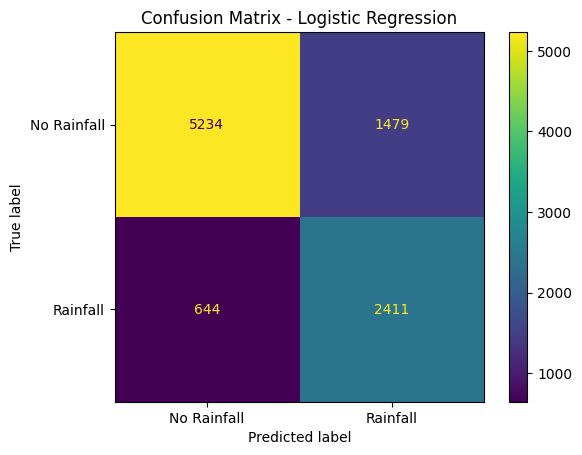

In [60]:
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=["no", "yes"],
    display_labels=["No Rainfall", "Rainfall"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [64]:
print(classification_report(
    y_test,
    best_predictions,
    labels=["no", "yes"],
    target_names=["No Rainfall", "Rainfall"],
    zero_division=0
))

              precision    recall  f1-score   support

 No Rainfall       0.89      0.78      0.83      6713
    Rainfall       0.62      0.79      0.69      3055

    accuracy                           0.78      9768
   macro avg       0.76      0.78      0.76      9768
weighted avg       0.81      0.78      0.79      9768



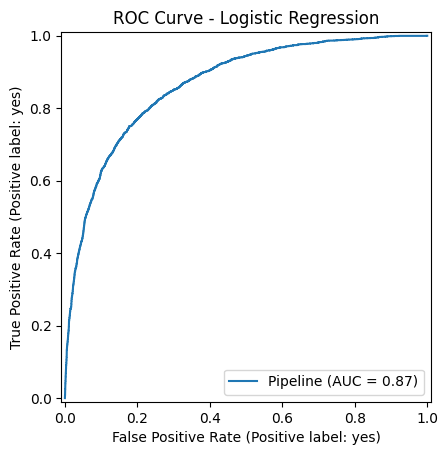

In [67]:
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    pos_label="yes"
)

plt.title(f"ROC Curve - {best_model_name}")
plt.show()

In [68]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": ["balanced", None]
}

grid_search = GridSearchCV(
    estimator=trained_models["Logistic Regression"],
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits


C:\Users\anami\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:1137: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan]
  warnings.warn(


Best Parameters: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}
Best Cross-Validation F1 Score: nan


In [69]:
best_tuned_model = grid_search.best_estimator_

tuned_predictions = best_tuned_model.predict(X_test)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nTuned Model Classification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    labels=["no", "yes"],
    target_names=["No Rainfall", "Rainfall"],
    zero_division=0
))

Best Parameters:
{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}

Tuned Model Classification Report:
              precision    recall  f1-score   support

 No Rainfall       0.89      0.78      0.83      6713
    Rainfall       0.62      0.80      0.70      3055

    accuracy                           0.78      9768
   macro avg       0.76      0.79      0.76      9768
weighted avg       0.81      0.78      0.79      9768



In [70]:
comparison = pd.DataFrame({
    "Model": ["Original Logistic Regression", "Tuned Logistic Regression"],
    "F1 Score": [
        results_df.loc[
            results_df["Model"] == "Logistic Regression", "F1 Score"
        ].iloc[0],
        f1_score(y_test, tuned_predictions, pos_label="yes", zero_division=0)
    ],
    "Accuracy": [
        results_df.loc[
            results_df["Model"] == "Logistic Regression", "Accuracy"
        ].iloc[0],
        accuracy_score(y_test, tuned_predictions)
    ]
})

comparison.round(4)

,Model,F1 Score,Accuracy
0,Original Logistic Regression,0.6943,0.7827
1,Tuned Logistic Regression,0.6962,0.7828


In [73]:
model_path = Path("models")
model_path.mkdir(parents=True, exist_ok=True)

joblib.dump(best_tuned_model, model_path / "rainfall_prediction_model.pkl")

print("Model saved successfully!")
print("Location:", model_path / "rainfall_prediction_model.pkl")

Model saved successfully!
Location: models\rainfall_prediction_model.pkl


In [74]:
loaded_model = joblib.load(model_path / "rainfall_prediction_model.pkl")

sample_data = X_test.iloc[:5]
sample_predictions = loaded_model.predict(sample_data)

prediction_result = pd.DataFrame({
    "Actual Rainfall": y_test.iloc[:5].to_numpy(),
    "Predicted Rainfall": sample_predictions
})

prediction_result

,Actual Rainfall,Predicted Rainfall
0,no,no
1,no,yes
2,no,no
3,no,no
4,yes,yes


In [76]:
def predict_rainfall(weather_data):
    prediction = loaded_model.predict(weather_data)
    probability = loaded_model.predict_proba(weather_data)

    yes_index = list(loaded_model.classes_).index("yes")

    return pd.DataFrame({
        "Predicted Rainfall": prediction,
        "Rainfall Probability (%)": (
            probability[:, yes_index] * 100
        ).round(2)
    })

In [77]:
predict_rainfall(X_test.iloc[:3])

,Predicted Rainfall,Rainfall Probability (%)
0,no,0.77
1,yes,82.96
2,no,9.41


In [93]:
import streamlit as st

project_path = Path.cwd()
app_path = project_path / "app.py"

print("Project folder:", project_path)
print("App file:", app_path)

Project folder: C:\Users\anami\Rainfall Prediction
App file: C:\Users\anami\Rainfall Prediction\app.py


In [95]:
app_code = r'''
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="Rainfall Prediction",
    page_icon="🌧️"
)

st.title("🌧️ Rainfall Prediction App")
st.write("Enter weather details to predict rainfall.")

model_path = (
    Path(__file__).parent
    / "models"
    / "rainfall_prediction_model.pkl"
)
model = joblib.load(model_path)

st.success("ML model loaded successfully!")

st.subheader("Weather Details")

with st.form("weather_form"):
    day = st.selectbox(
        "Day",
        ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"]
    )

    pressure = st.number_input(
        "Pressure", min_value=850.0, max_value=1100.0,
        value=1010.0
    )
    maxtemp = st.number_input(
        "Maximum Temperature (°C)", min_value=-30.0,
        max_value=60.0, value=30.0
    )
    temperature = st.number_input(
        "Temperature (°C)", min_value=-30.0,
        max_value=60.0, value=25.0
    )
    mintemp = st.number_input(
        "Minimum Temperature (°C)", min_value=-40.0,
        max_value=50.0, value=20.0
    )
    dewpoint = st.number_input(
        "Dew Point (°C)", min_value=-50.0,
        max_value=40.0, value=18.0
    )
    humidity = st.slider("Humidity (%)", 0, 100, 70)
    cloud = st.slider("Cloud Cover (%)", 0, 100, 60)
    sunshine = st.number_input(
        "Sunshine (hours)", min_value=0.0,
        max_value=24.0, value=5.0
    )
    winddirection = st.selectbox(
        "Wind Direction",
        ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    )
    windspeed = st.number_input(
        "Wind Speed", min_value=0.0,
        max_value=200.0, value=10.0
    )

    submitted = st.form_submit_button("Predict Rainfall")

if submitted:
    weather_data = pd.DataFrame([{
        "day": day,
        "pressure": pressure,
        "maxtemp": maxtemp,
        "temperature": temperature,
        "mintemp": mintemp,
        "dewpoint": dewpoint,
        "humidity": humidity,
        "cloud": cloud,
        "sunshine": sunshine,
        "winddirection": winddirection,
        "windspeed": windspeed
    }])

    try:
        prediction = model.predict(weather_data)[0]

        if prediction == "yes":
            st.success("🌧️ Prediction: Rainfall expected")
        else:
            st.info("☀️ Prediction: No rainfall expected")

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(weather_data)[0]
            yes_index = list(model.classes_).index("yes")
            st.metric(
                "Estimated Rainfall Probability",
                f"{probabilities[yes_index] * 100:.2f}%"
            )

    except Exception as error:
        st.error(f"Prediction failed: {error}")

st.caption("Predictions are estimates, not guaranteed weather forecasts.")
'''

app_path.write_text(app_code, encoding="utf-8")
print("app.py saved successfully:", app_path)

app.py saved successfully: C:\Users\anami\Rainfall Prediction\app.py
